# 01 · EDA & Data Cleaning — Student Dropout Risk
**Project 1 of 5 — End-to-End ML Pipeline.** Goal: build an *early-warning system* that flags students at risk of dropping out, so a college can help them in time.

| Notebook | Topic |
|---|---|
| **01 (this)** | Understand and clean the data |
| 02 | Feature engineering, split, baselines |
| 03 | LightGBM / XGBoost, MLflow tracking, SHAP, threshold choice |

**Data:** 4,424 students of a Portuguese higher-education institute (UCI *Predict Students' Dropout and Academic Success*; Realinho et al., 2021). Each row is one student with enrolment info, family background, 1st- and 2nd-semester results and economic context. Outcome: `Dropout`, `Enrolled` or `Graduate`.

## 1. Load

In [1]:
import sys, warnings; warnings.filterwarnings('ignore'); sys.path.insert(0, '.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from src.features import *
sns.set_theme(style='whitegrid')
raw = pd.read_csv('data/students_raw.csv', sep=None, engine='python', encoding='utf-8-sig')
print(raw.shape)

(4424, 35)


In [2]:
raw.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:
raw.columns.tolist()

['Marital status',
 'Application mode',
 'Application order',
 'Course',
 'Daytime/evening attendance',
 'Previous qualification',
 'Nacionality',
 "Mother's qualification",
 "Father's qualification",
 "Mother's occupation",
 "Father's occupation",
 'Displaced',
 'Educational special needs',
 'Debtor',
 'Tuition fees up to date',
 'Gender',
 'Scholarship holder',
 'Age at enrollment',
 'International',
 'Curricular units 1st sem (credited)',
 'Curricular units 1st sem (enrolled)',
 'Curricular units 1st sem (evaluations)',
 'Curricular units 1st sem (approved)',
 'Curricular units 1st sem (grade)',
 'Curricular units 1st sem (without evaluations)',
 'Curricular units 2nd sem (credited)',
 'Curricular units 2nd sem (enrolled)',
 'Curricular units 2nd sem (evaluations)',
 'Curricular units 2nd sem (approved)',
 'Curricular units 2nd sem (grade)',
 'Curricular units 2nd sem (without evaluations)',
 'Unemployment rate',
 'Inflation rate',
 'GDP',
 'Target']

Column names have spaces, apostrophes, a BOM character at the start and a typo (`Nacionality`). Our shared `snake()` function makes them clean identifiers (the *same* function is used later in the API, so training and serving never disagree).

In [4]:
df = load_raw('data/students_raw.csv'); df.columns.tolist()

['marital_status',
 'application_mode',
 'application_order',
 'course',
 'daytime_evening_attendance',
 'previous_qualification',
 'nacionality',
 'mothers_qualification',
 'fathers_qualification',
 'mothers_occupation',
 'fathers_occupation',
 'displaced',
 'educational_special_needs',
 'debtor',
 'tuition_fees_up_to_date',
 'gender',
 'scholarship_holder',
 'age_at_enrollment',
 'international',
 'curricular_units_1st_sem_credited',
 'curricular_units_1st_sem_enrolled',
 'curricular_units_1st_sem_evaluations',
 'curricular_units_1st_sem_approved',
 'curricular_units_1st_sem_grade',
 'curricular_units_1st_sem_without_evaluations',
 'curricular_units_2nd_sem_credited',
 'curricular_units_2nd_sem_enrolled',
 'curricular_units_2nd_sem_evaluations',
 'curricular_units_2nd_sem_approved',
 'curricular_units_2nd_sem_grade',
 'curricular_units_2nd_sem_without_evaluations',
 'unemployment_rate',
 'inflation_rate',
 'gdp',
 'target']

In [5]:
df.shape

(4424, 35)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   marital_status                                4424 non-null   int64  
 1   application_mode                              4424 non-null   int64  
 2   application_order                             4424 non-null   int64  
 3   course                                        4424 non-null   int64  
 4   daytime_evening_attendance                    4424 non-null   int64  
 5   previous_qualification                        4424 non-null   int64  
 6   nacionality                                   4424 non-null   int64  
 7   mothers_qualification                         4424 non-null   int64  
 8   fathers_qualification                         4424 non-null   int64  
 9   mothers_occupation                            4424 non-null   int64  
 10 

In [7]:
df.dtypes.value_counts()

int64      29
float64     5
str         1
Name: count, dtype: int64

## 2. Data quality checks

In [8]:
print('missing values:', int(df.isna().sum().sum())); print('duplicate rows:', int(df.duplicated().sum()))

missing values: 0
duplicate rows: 0


In [9]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
marital_status,4424.0,1.18,0.61,1.00,1.00,1.00,1.00,6.00
application_mode,4424.0,6.89,5.30,1.00,1.00,8.00,12.00,18.00
application_order,4424.0,1.73,1.31,0.00,1.00,1.00,2.00,9.00
course,4424.0,9.90,4.33,1.00,6.00,10.00,13.00,17.00
daytime_evening_attendance,4424.0,0.89,0.31,0.00,1.00,1.00,1.00,1.00
previous_qualification,4424.0,2.53,3.96,1.00,1.00,1.00,1.00,17.00
nacionality,4424.0,1.25,1.75,1.00,1.00,1.00,1.00,21.00
mothers_qualification,4424.0,12.32,9.03,1.00,2.00,13.00,22.00,29.00
fathers_qualification,4424.0,16.46,11.04,1.00,3.00,14.00,27.00,34.00
mothers_occupation,4424.0,7.32,4.00,1.00,5.00,6.00,10.00,32.00


In [10]:
(df.nunique().sort_values()).to_frame('unique values').T

,daytime_evening_attendance,debtor,tuition_fees_up_to_date,gender,educational_special_needs,displaced,international,scholarship_holder,target,marital_status,...,curricular_units_1st_sem_enrolled,mothers_qualification,curricular_units_2nd_sem_evaluations,mothers_occupation,fathers_qualification,curricular_units_1st_sem_evaluations,fathers_occupation,age_at_enrollment,curricular_units_2nd_sem_grade,curricular_units_1st_sem_grade
unique values,2,2,2,2,2,2,2,2,3,6,...,23,29,30,32,34,35,46,46,786,805


Many columns have few unique values: they are **codes for categories** (e.g. `course` = 1…17), not quantities. Treating them as numbers would be wrong — we mark them as categorical later.

In [11]:
print('Categorical code columns:', CATEGORICAL); print('Binary columns:', BINARY)

Categorical code columns: ['marital_status', 'application_mode', 'application_order', 'course', 'daytime_evening_attendance', 'previous_qualification', 'nacionality', 'mothers_qualification', 'fathers_qualification', 'mothers_occupation', 'fathers_occupation']
Binary columns: ['displaced', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'international']


In [12]:
df[CATEGORICAL].nunique().sort_values(ascending=False).to_frame('levels')

,levels
fathers_occupation,46
fathers_qualification,34
mothers_occupation,32
mothers_qualification,29
nacionality,21
application_mode,18
course,17
previous_qualification,17
application_order,8
marital_status,6


### 2.1 Impossible or suspicious values

In [13]:
checks = {
 'age at enrollment < 16': (df.age_at_enrollment<16).sum(),
 'age at enrollment > 60': (df.age_at_enrollment>60).sum(),
 'approved > enrolled (1st sem)': (df.curricular_units_1st_sem_approved>df.curricular_units_1st_sem_enrolled).sum(),
 'approved > enrolled (2nd sem)': (df.curricular_units_2nd_sem_approved>df.curricular_units_2nd_sem_enrolled).sum(),
 'grade > 20 (1st sem)': (df.curricular_units_1st_sem_grade>20).sum(),
 'negative values in unit counts': (df.filter(like='curricular_units').lt(0)).sum().sum(),
}
pd.Series(checks).to_frame('rows')

,rows
age at enrollment < 16,0
age at enrollment > 60,3
approved > enrolled (1st sem),0
approved > enrolled (2nd sem),0
grade > 20 (1st sem),0
negative values in unit counts,0


In [14]:
df[df.curricular_units_1st_sem_approved>df.curricular_units_1st_sem_enrolled][['curricular_units_1st_sem_credited','curricular_units_1st_sem_enrolled','curricular_units_1st_sem_approved']].head()

,curricular_units_1st_sem_credited,curricular_units_1st_sem_enrolled,curricular_units_1st_sem_approved


`approved > enrolled` can happen legitimately: **credited** units (recognised from earlier study) can be approved without being enrolled this semester. We keep these rows.

In [15]:
zero_enr = (df.curricular_units_1st_sem_enrolled==0).sum(); print('students enrolled in 0 units in sem 1:', zero_enr, f'({zero_enr/len(df):.1%})')

students enrolled in 0 units in sem 1: 180 (4.1%)


In [16]:
df.loc[df.curricular_units_1st_sem_enrolled==0,'target'].value_counts()

target
Dropout     77
Graduate    75
Enrolled    28
Name: count, dtype: int64

Students with **no units enrolled** in semester 1 are a small group (4%) with a high dropout rate (77 of 180 ≈ 43%, versus 32% overall) — but 75 of them still graduated (probably through credited units). It is real, not an error, so we keep them.

## 3. The target

In [17]:
df['target'].value_counts()

target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

In [18]:
df['target'].value_counts(normalize=True).mul(100).round(1)

target
Graduate    49.9
Dropout     32.1
Enrolled    17.9
Name: proportion, dtype: float64

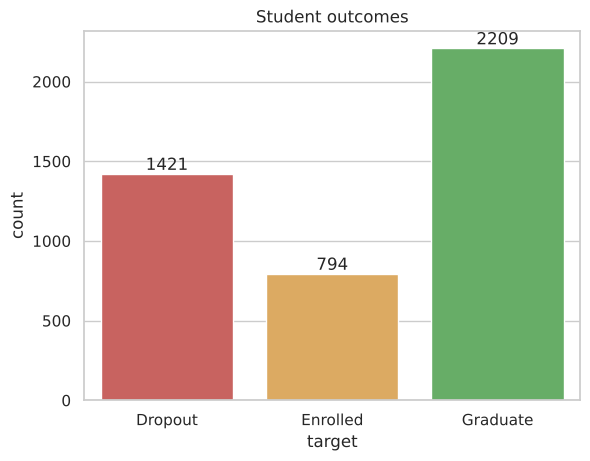

In [19]:
order=['Dropout','Enrolled','Graduate']
ax=sns.countplot(data=df,x='target',order=order,palette=['#d9534f','#f0ad4e','#5cb85c']); ax.set_title('Student outcomes'); [ax.annotate(int(p.get_height()),(p.get_x()+.4,p.get_height()),ha='center',va='bottom') for p in ax.patches]; plt.show()

### Business framing — what exactly do we predict?
A college wants to know **who is at risk of dropping out**. So we define a binary target:

| Original | `dropout` |
|---|---|
| Dropout | **1** |
| Graduate, Enrolled | 0 |

*Enrolled* students have not finished yet, but they have not dropped out either.

In [20]:
df = add_target(df)
print('Dropout rate: %.1f%%' % (df.dropout.mean()*100))
df.dropout.value_counts()

Dropout rate: 32.1%


dropout
0    3003
1    1421
Name: count, dtype: int64

About 1 in 3 students drops out — imbalanced but not extreme, so accuracy alone would mislead (always predicting “no dropout” scores ≈ 68%). We will focus on **recall, precision, F1, ROC-AUC and PR-AUC**.

## 4. Univariate analysis

### 4.1 Age

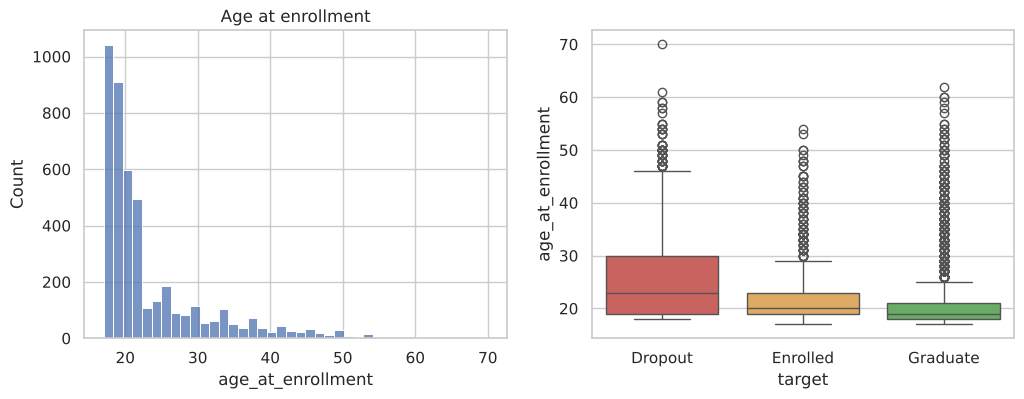

In [21]:
fig,ax=plt.subplots(1,2,figsize=(12,4)); sns.histplot(df.age_at_enrollment,bins=40,ax=ax[0]); ax[0].set_title('Age at enrollment'); sns.boxplot(data=df,x='target',y='age_at_enrollment',order=order,ax=ax[1],palette=['#d9534f','#f0ad4e','#5cb85c']); plt.show()

In [22]:
df.groupby('target').age_at_enrollment.describe().round(1)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
Dropout,1421.0,26.1,8.7,18.0,19.0,23.0,30.0,70.0
Enrolled,794.0,22.4,6.3,17.0,19.0,20.0,23.0,54.0
Graduate,2209.0,21.8,6.7,17.0,18.0,19.0,21.0,62.0


In [23]:
bins=pd.cut(df.age_at_enrollment,[16,19,21,25,30,40,80]); df.groupby(bins).dropout.agg(['mean','count']).round(3)

,mean,count
age_at_enrollment,,
"(16, 19]",0.210,1952
"(19, 21]",0.245,921
"(21, 25]",0.399,506
"(25, 30]",0.598,383
"(30, 40]",0.551,437
"(40, 80]",0.507,225


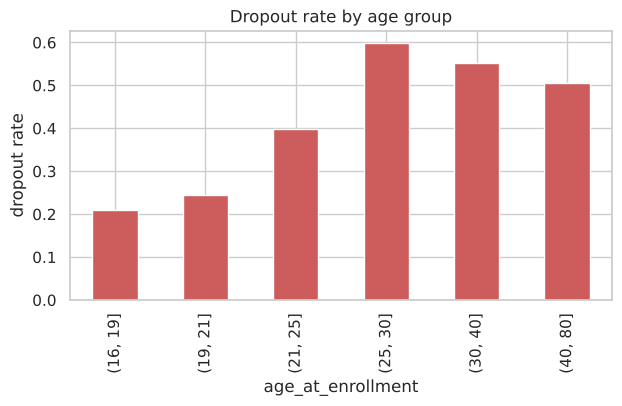

In [24]:
df.groupby(bins).dropout.mean().plot(kind='bar',color='indianred',figsize=(7,3.5)); plt.ylabel('dropout rate'); plt.title('Dropout rate by age group'); plt.show()

Older students (mature entrants, often working) drop out far more often than 18–19-year-olds.

### 4.2 Money & support flags

In [25]:
flags=['debtor','tuition_fees_up_to_date','scholarship_holder','displaced','gender','international','educational_special_needs']
rows=[]
for f in flags:
    g=df.groupby(f).dropout.agg(['mean','count']); rows.append({'feature':f,'rate if 0':g.loc[0,'mean'],'rate if 1':g.loc[1,'mean'],'n(1)':g.loc[1,'count']})
pd.DataFrame(rows).set_index('feature').round(3)

,rate if 0,rate if 1,n(1)
feature,,,
debtor,0.283,0.620,503
tuition_fees_up_to_date,0.866,0.247,3896
scholarship_holder,0.387,0.122,1099
displaced,0.376,0.276,2426
gender,0.251,0.451,1556
international,0.322,0.291,110
educational_special_needs,0.321,0.333,51


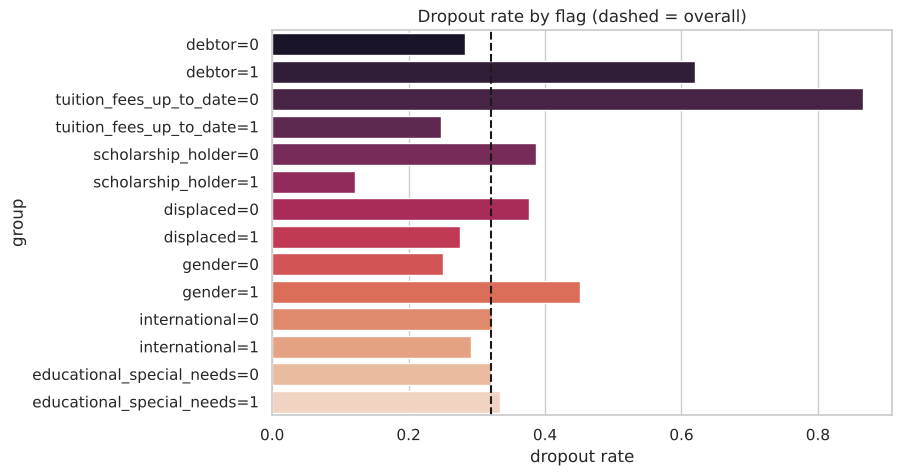

In [26]:
t=pd.DataFrame([{'feature':f,'group':f'{f}={v}','dropout rate':df[df[f]==v].dropout.mean()} for f in flags for v in (0,1)])
plt.figure(figsize=(8,5)); sns.barplot(data=t,y='group',x='dropout rate',palette='rocket'); plt.axvline(df.dropout.mean(),color='k',ls='--'); plt.title('Dropout rate by flag (dashed = overall)'); plt.show()

Strong effects: **tuition fees not up to date** and **being a debtor** raise dropout risk a lot; **scholarship holders** drop out far less.

### 4.3 Course

In [27]:
c=df.groupby('course').dropout.agg(['mean','count']).sort_values('mean'); c.round(3)

,mean,count
course,,
12,0.154,766
10,0.183,355
5,0.226,226
6,0.267,337
15,0.305,331
3,0.330,215
9,0.353,380
14,0.354,268
11,0.381,252


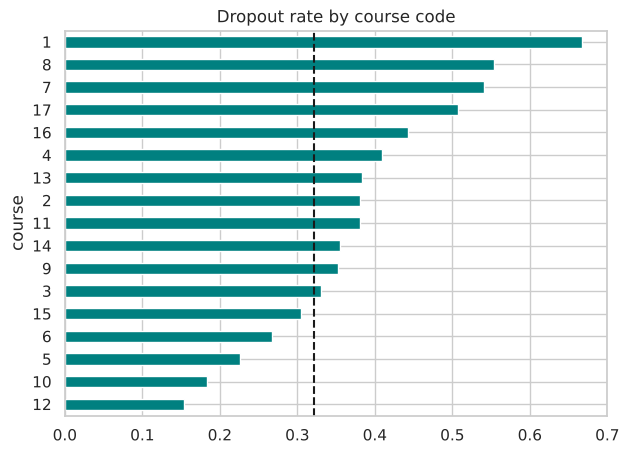

In [28]:
c['mean'].plot(kind='barh',figsize=(7,5),color='teal'); plt.axvline(df.dropout.mean(),color='k',ls='--'); plt.title('Dropout rate by course code'); plt.show()

### 4.4 Application mode, marital status, attendance

In [29]:
for col in ['application_mode','marital_status','daytime_evening_attendance','application_order']:
    g=df.groupby(col).dropout.agg(['mean','count']); print(col); print(g[g['count']>=30].round(3).T); print()

application_mode
application_mode        1        4       6       7        8        9   \
mean                 0.202    0.612   0.167   0.132    0.294    0.363   
count             1708.000  139.000  30.000  38.000  872.000  124.000   

application_mode       12      13       14       15      16      17  
mean                0.554   0.442    0.369    0.296   0.339   0.114  
count             785.000  77.000  312.000  213.000  59.000  35.000  

marital_status
marital_status         1        2       4
mean               0.302    0.472   0.462
count           3919.000  379.000  91.000

daytime_evening_attendance
daytime_evening_attendance        0         1
mean                          0.429     0.308
count                       483.000  3941.000

application_order
application_order         1        2        3        4        5        6
mean                  0.348    0.274    0.246    0.233    0.344    0.226
count              3026.000  547.000  309.000  249.000  154.000  137.000



## 5. Academic performance — the strongest signals

In [30]:
acad=['curricular_units_1st_sem_enrolled','curricular_units_1st_sem_approved','curricular_units_1st_sem_grade','curricular_units_2nd_sem_enrolled','curricular_units_2nd_sem_approved','curricular_units_2nd_sem_grade']
df.groupby('target')[acad].mean().round(2).T

target,Dropout,Enrolled,Graduate
curricular_units_1st_sem_enrolled,5.82,5.96,6.67
curricular_units_1st_sem_approved,2.55,4.32,6.23
curricular_units_1st_sem_grade,7.26,11.13,12.64
curricular_units_2nd_sem_enrolled,5.78,5.94,6.63
curricular_units_2nd_sem_approved,1.94,4.06,6.18
curricular_units_2nd_sem_grade,5.90,11.12,12.70


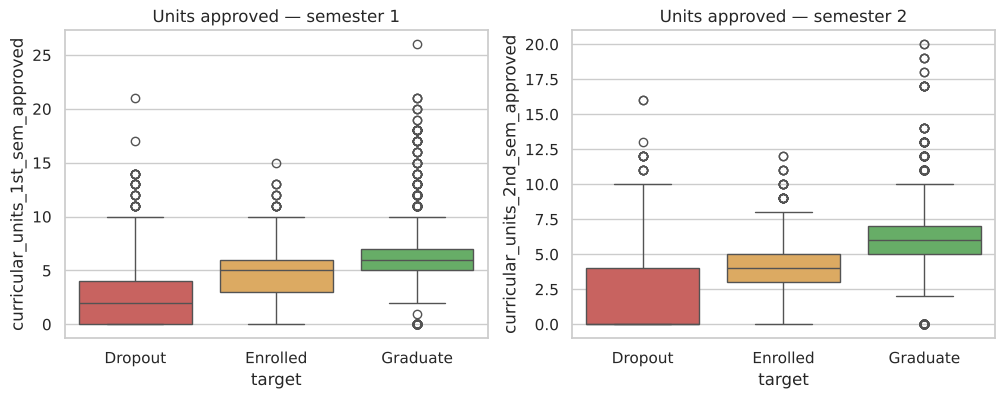

In [31]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=df,x='target',y='curricular_units_1st_sem_approved',order=order,ax=ax[0],palette=['#d9534f','#f0ad4e','#5cb85c']); ax[0].set_title('Units approved — semester 1')
sns.boxplot(data=df,x='target',y='curricular_units_2nd_sem_approved',order=order,ax=ax[1],palette=['#d9534f','#f0ad4e','#5cb85c']); ax[1].set_title('Units approved — semester 2'); plt.show()

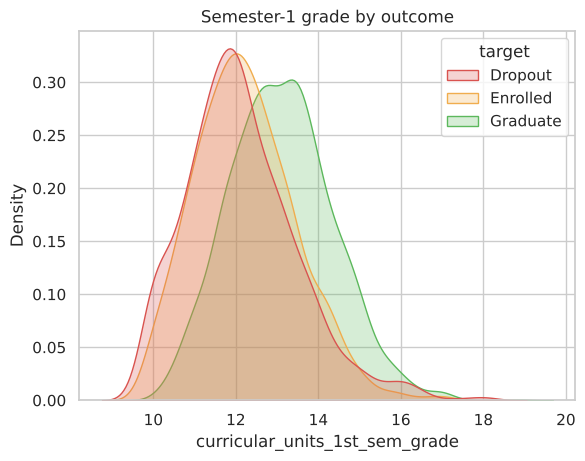

In [32]:
sns.kdeplot(data=df[df.curricular_units_1st_sem_grade>0],x='curricular_units_1st_sem_grade',hue='target',hue_order=order,common_norm=False,palette=['#d9534f','#f0ad4e','#5cb85c'],fill=True); plt.title('Semester-1 grade by outcome'); plt.show()

In [33]:
p=df.curricular_units_1st_sem_approved.clip(upper=10); df.groupby(p).dropout.agg(['mean','count']).round(3).T

curricular_units_1st_sem_approved,0,1,2,3,4,5,6,7,8,9,10
mean,0.794,0.732,0.7,0.517,0.365,0.201,0.1,0.07,0.093,0.2,0.176
count,718.000,127.000,160.0,269.000,433.000,723.000,1171.0,471.00,108.000,40.0,204.000


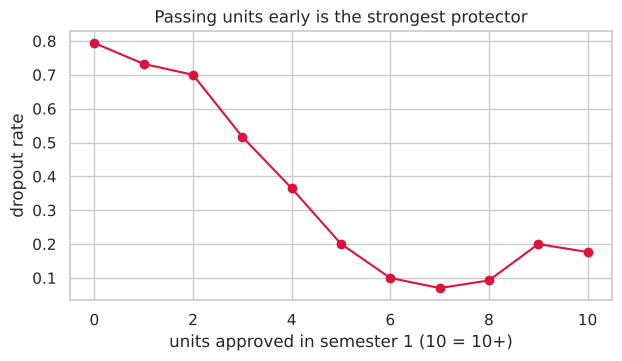

In [34]:
df.groupby(p).dropout.mean().plot(marker='o',figsize=(7,3.5),color='crimson'); plt.xlabel('units approved in semester 1 (10 = 10+)'); plt.ylabel('dropout rate'); plt.title('Passing units early is the strongest protector'); plt.show()

Students who pass **0–2 units** in the first semester drop out most of the time; students who pass 6+ rarely do. This is why a *first-semester* early-warning model is useful: it can act while there is still time.

## 6. Economic context

In [35]:
df.groupby('target')[['unemployment_rate','inflation_rate','gdp']].mean().round(2)

,unemployment_rate,inflation_rate,gdp
target,,,
Dropout,11.62,1.28,-0.15
Enrolled,11.27,1.21,0.05
Graduate,11.64,1.20,0.08


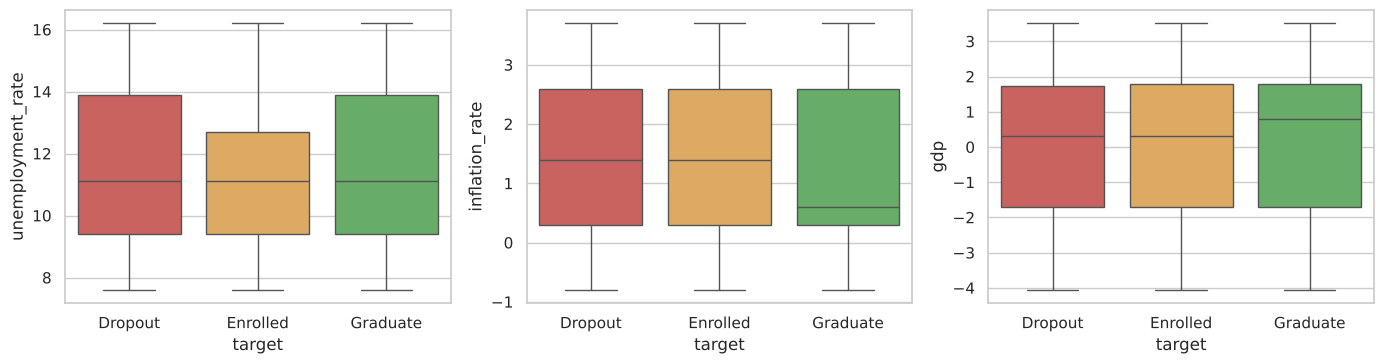

In [36]:
fig,ax=plt.subplots(1,3,figsize=(14,3.8))
for a,c in zip(ax,['unemployment_rate','inflation_rate','gdp']): sns.boxplot(data=df,x='target',y=c,order=order,ax=a,palette=['#d9534f','#f0ad4e','#5cb85c'])
plt.tight_layout(); plt.show()

Macro-economic variables differ little between outcomes — they are the same for everyone who enrolled in the same period, so they say little about *individual* risk.

## 7. Statistical tests (is the difference real?)

In [37]:
from scipy.stats import chi2_contingency, mannwhitneyu
rows=[]
for f in BINARY:
    ct=pd.crosstab(df[f],df.dropout); chi,p,_,_=chi2_contingency(ct); n_=ct.values.sum(); cv=np.sqrt(chi/n_); rows.append((f,round(chi,1),p,round(cv,3)))
pd.DataFrame(rows,columns=['binary feature','chi2','p-value','Cramér V']).sort_values('Cramér V',ascending=False)

,binary feature,chi2,p-value,Cramér V
3,tuition_fees_up_to_date,811.9,1.373782e-178,0.428
5,scholarship_holder,265.1,1.324567e-59,0.245
2,debtor,231.3,3.134874e-52,0.229
4,gender,183.2,9.876586e-42,0.203
0,displaced,50.4,1.247433e-12,0.107
6,international,0.3,5.581023e-01,0.009
1,educational_special_needs,0.0,9.714462e-01,0.001


In [38]:
num=['age_at_enrollment','curricular_units_1st_sem_approved','curricular_units_1st_sem_grade','curricular_units_2nd_sem_approved','curricular_units_2nd_sem_grade','unemployment_rate','inflation_rate','gdp']
rows=[]
for c in num:
    a=df.loc[df.dropout==1,c]; b=df.loc[df.dropout==0,c]; u,p=mannwhitneyu(a,b); auc=u/(len(a)*len(b)); rows.append((c,p,round(auc,3)))
pd.DataFrame(rows,columns=['feature','p-value','AUC (P(dropout value > other))']).sort_values('AUC (P(dropout value > other))')

,feature,p-value,AUC (P(dropout value > other))
3,curricular_units_2nd_sem_approved,0.000000e+00,0.145
1,curricular_units_1st_sem_approved,5.900210e-265,0.182
4,curricular_units_2nd_sem_grade,3.451159e-252,0.186
2,curricular_units_1st_sem_grade,1.823116e-190,0.227
7,gdp,1.670292e-04,0.465
5,unemployment_rate,5.260396e-01,0.506
6,inflation_rate,1.233715e-01,0.514
0,age_at_enrollment,2.055321e-77,0.671


An AUC far from 0.5 (e.g. 0.2 for *units approved*) means the feature alone separates dropouts from the rest very well; ≈ 0.5 (economic variables) means it barely helps.

## 8. Correlations

In [39]:
num_cols=df.select_dtypes('number').drop(columns=['dropout']).columns
corr=df[list(num_cols)+['dropout']].corr()['dropout'].drop('dropout').sort_values()
corr.round(3).head(8).to_frame('corr with dropout')

,corr with dropout
curricular_units_2nd_sem_grade,-0.572
curricular_units_2nd_sem_approved,-0.570
curricular_units_1st_sem_grade,-0.481
curricular_units_1st_sem_approved,-0.479
tuition_fees_up_to_date,-0.429
scholarship_holder,-0.245
curricular_units_2nd_sem_evaluations,-0.155
curricular_units_2nd_sem_enrolled,-0.142


In [40]:
corr.round(3).tail(8).to_frame('corr with dropout')

,corr with dropout
mothers_qualification,0.059
curricular_units_2nd_sem_without_evaluations,0.080
previous_qualification,0.092
marital_status,0.094
application_mode,0.189
gender,0.204
debtor,0.229
age_at_enrollment,0.254


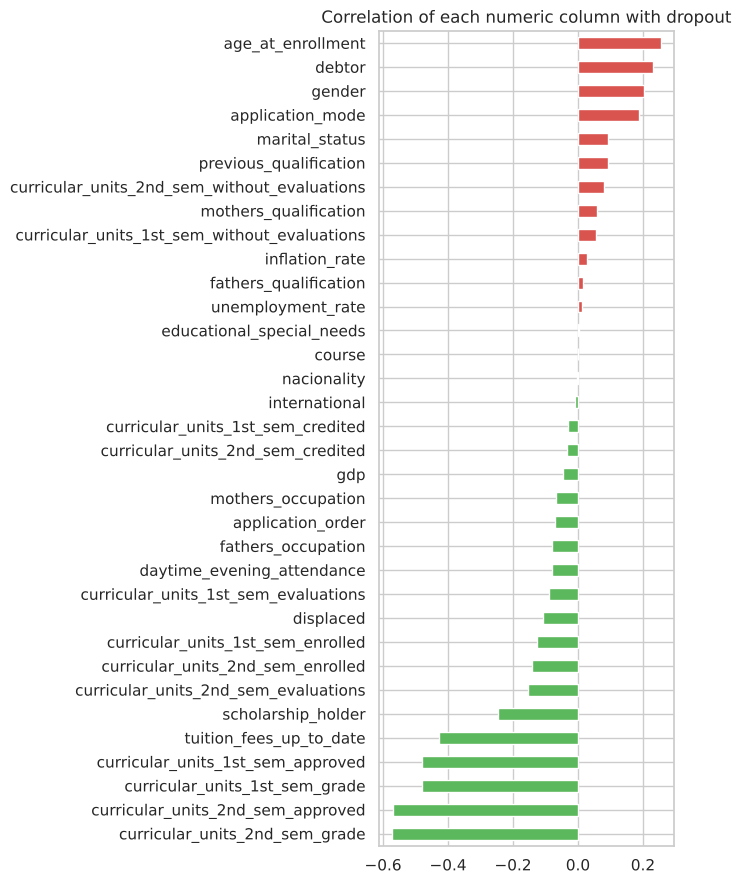

In [41]:
corr.plot(kind='barh',figsize=(7,9),color=np.where(corr<0,'#5cb85c','#d9534f')); plt.title('Correlation of each numeric column with dropout'); plt.tight_layout(); plt.show()

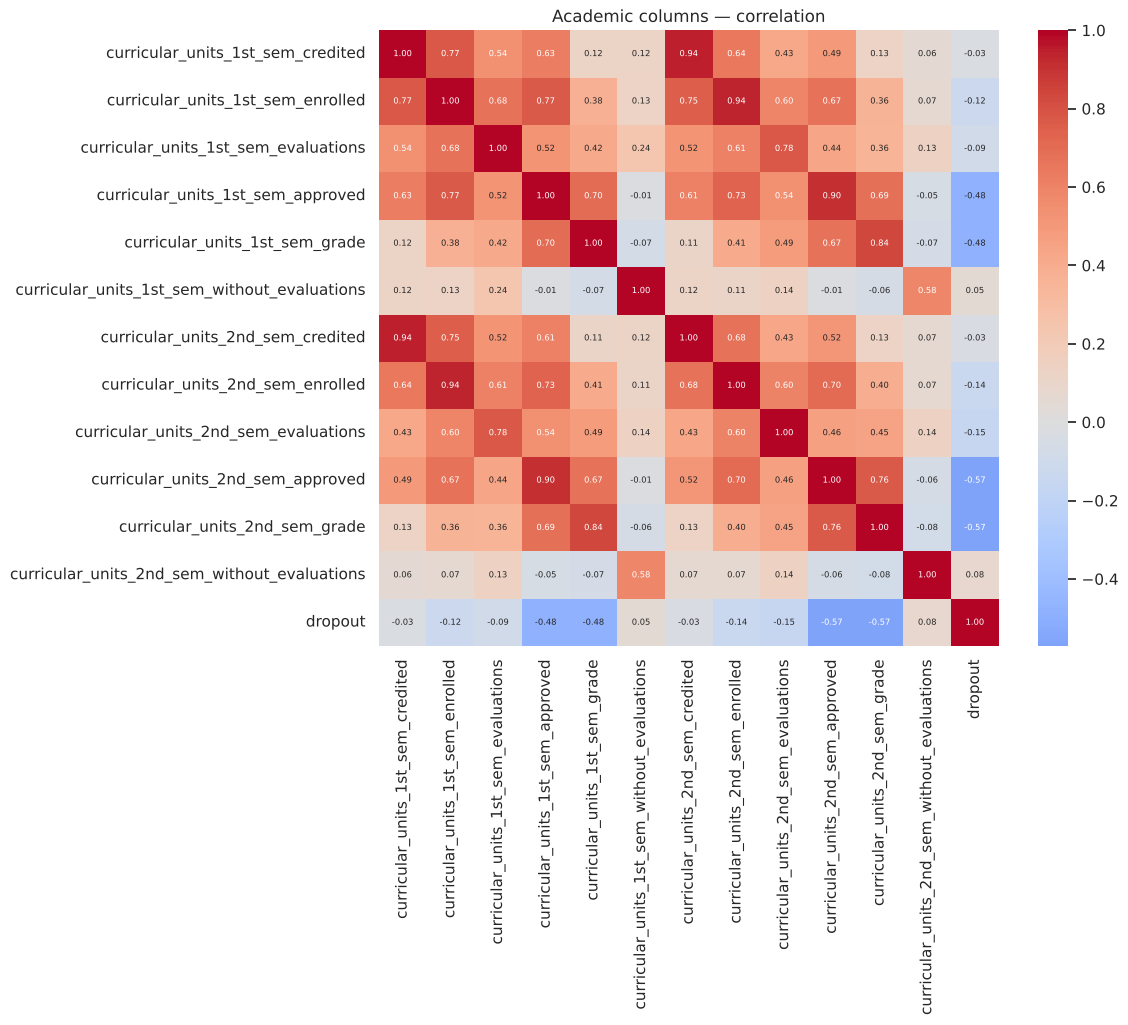

In [42]:
acad_cols=[c for c in df.columns if 'curricular' in c]
plt.figure(figsize=(10,8)); sns.heatmap(df[acad_cols+['dropout']].corr(),cmap='coolwarm',center=0,annot=True,fmt='.2f',annot_kws={'size':6}); plt.title('Academic columns — correlation'); plt.show()

Sem-1 and sem-2 columns are highly correlated with each other — normal for the same student, and fine for tree models.

## 9. Leakage thinking (important for real ML projects)

**When** would the model be used? To help students, it should run **early**. Two realistic moments:

| Stage | Data available | Name in code |
|---|---|---|
| After semester 1 | enrolment, family, finances, sem-1 results | `end_of_sem1` (early warning) |
| After semester 2 | everything above + sem-2 results | `end_of_sem2` (more accurate, later) |

Using semester-2 data in a model meant for semester 1 would be **data leakage** (information from the future). We build **both** and compare — the accuracy-vs-earliness trade-off is a key finding.

In [43]:
print('end_of_sem1 features:', len(feature_columns(add_target(df),'end_of_sem1')))
print('end_of_sem2 features:', len(feature_columns(add_target(df),'end_of_sem2')))

end_of_sem1 features: 28
end_of_sem2 features: 34


In [44]:
print(sem2_columns(df))

['curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade', 'curricular_units_2nd_sem_without_evaluations']


## 10. Cleaning decisions & save

In [45]:
print('rows:',len(df),'| duplicates:',df.duplicated().sum(),'| missing:',int(df.isna().sum().sum()))

rows: 4424 | duplicates: 0 | missing: 0


In [46]:
df.to_csv('data/students_clean.csv',index=False); print('saved data/students_clean.csv', df.shape)

saved data/students_clean.csv (4424, 36)


## 11. Findings
| Finding | Evidence |
|---|---|
| ≈ 32% of students drop out | target counts |
| No missing values, no duplicates | quality checks |
| Unpaid tuition / debtor ⇒ much higher risk | rates by flag |
| Scholarship ⇒ lower risk | rates by flag |
| Older entrants drop out more | rate by age group |
| Units passed in semester 1 is the strongest signal | boxplots, AUC test |
| Economic variables add little | boxplots, tests |

**Next:** [02 – Features, split & baselines](02_features_split_baselines.ipynb)